<div align="center"><img src="https://github.com/user-attachments/assets/5d3a38ab-b20c-4103-b401-cddc112bfac8" width="300" alt="NOVA IMS Logo">

  <br>
  <br>
  <b>Master in Data Science and Advanced Analytics</b>

  <b>Computational Intelligence for Optimization </b>

  2025–2026

  <h1><b> Vermeer’s <i>Girl with a pearl earing</i>: 100 triangles Challenge <b></h1>
</div>



### <span style="color:#89AC76;">C22_Natural_Selection | Members</span>

<table>
  <thead style="color:#89AC76;">
    <tr>
      <th>Name</th>
      <th>Student ID</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Afonso Hermenegildo</td>
      <td>20221958</td>
    </tr>
    <tr>
      <td>André Ferreira</td>
      <td>20250398</td>
    </tr>
    <tr>
      <td>Marco Martins</td>
      <td>20221951</td>
    </tr>
    <tr>
      <td>Maria Francisca Gonçalves</td>
      <td>20221942</td>
    </tr>
  </tbody>
</table>

## <span style="color:#89AC76;">Table of Contents</span>


[ADICIONAR!!]

---
<h2 id="chapter1" style="color:#89AC76;">1. Imports</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

All libraries used throughout the notebook are imported here. We rely on `Pillow` and `numpy` for image handling, `matplotlib` for visualisation, and `scipy` for statistical testing. The class-provided `library` module is also imported to access the base `Solution` class.

In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), "scripts"))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from functools import partial #pass a pre-applied selector via functools.partial.
from copy import deepcopy

from scripts.triangle_sol import TriangleSolution, AdaptiveTriangleSolution
from scripts.ga import genetic_algorithm
from scripts.ga_utils import get_fitness
from scripts.experiments import plot_fitness_history
from scripts.new_hill_climbing import hill_climbing, plot_hill_climbing_log
from operators import (
    # selection
    roulette_wheel_selection,
    rank_based_selection,
    tournament_selection,
    # crossover
    one_point_crossover,
    two_point_crossover,
    uniform_crossover,
    # mutation
    triangle_gaussian_mutation,
    triangle_gaussian_color_mutation,
    triangle_gaussian_vertex_mutation,
    triangle_reset_gene_mutation,
    triangle_reset_mutation,
    triangle_layer_swap_mutation,
    # new fitness sharing
    representation_vectors,
    sharing_function,
    compute_counts,
    apply_fitness_sharing, 
    fitness_sharing_selection, 
    measure_diversity,
    AutomaticFitnessSharingSelection,
    AdvancedFitnessSharingSelection,
    GenerationCounterCallback
)
from scripts.statistical_comparison import run_ga_statistical_comparison
from scripts.statistical_comparison import plot_statistical_comparison


""" # fitness sharing
    representation_vectors,
    sharing_function,
    compute_counts,
    apply_fitness_sharing, 
    fitness_sharing_selection, 
    measure_diversity, """

' # fitness sharing\n    representation_vectors,\n    sharing_function,\n    compute_counts,\n    apply_fitness_sharing, \n    fitness_sharing_selection, \n    measure_diversity, '

---
<h2 id="chapter2" style="color:#89AC76;">2. Target Image Loading &amp; Inspection</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

We load the 300×400 target image and convert it to a NumPy array. Keeping the array in memory as a global constant avoids redundant I/O during fitness evaluations, which are called thousands of times per run.

Image size  : 300 x 400 px
Array shape : (400, 300, 4)


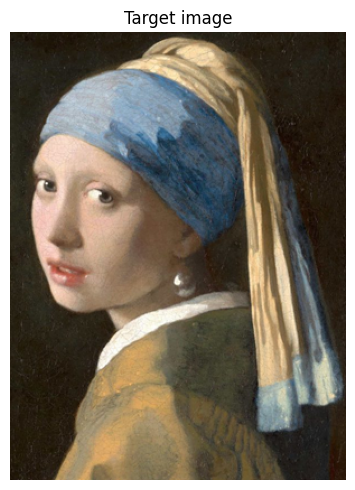

In [2]:
IMG_PATH = "project_info/girl_pearl_earing.png"

target_img = Image.open(IMG_PATH).convert("RGBA")
target_arr = np.array(target_img, dtype=np.float32)

IMG_WIDTH, IMG_HEIGHT = target_img.size   # (width, height) from PIL

print(f"Image size  : {IMG_WIDTH} x {IMG_HEIGHT} px")
print(f"Array shape : {target_arr.shape}")

# Wire the target into TriangleSolution so every instance uses it automatically
TriangleSolution.target_array = target_arr
TriangleSolution.__init__.__defaults__  # sanity-check defaults still present

plt.figure(figsize=(4, 5))
plt.imshow(target_arr / 255)
plt.title("Target image")
plt.axis("off")
plt.tight_layout()
plt.show()

Now, we will check the distribution of our data.

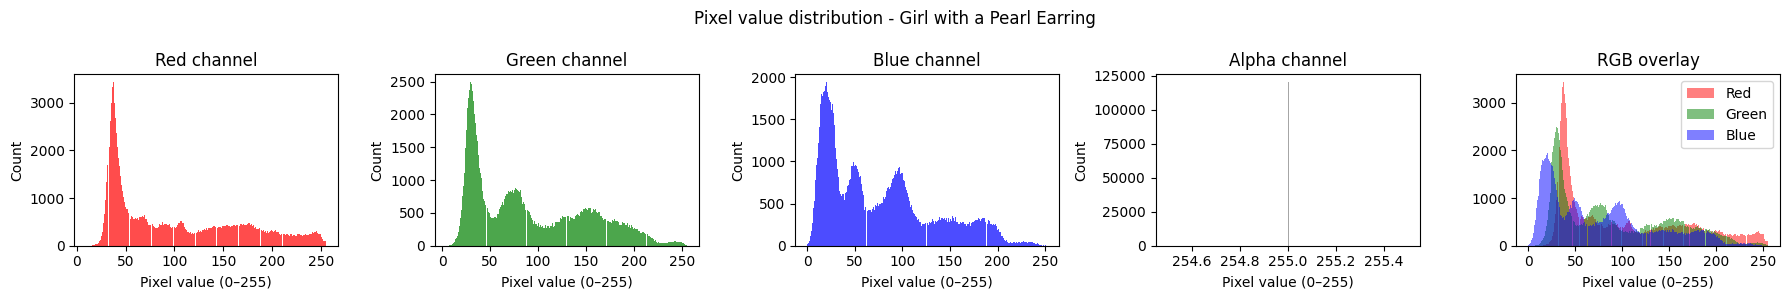

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
channels = ['Red', 'Green', 'Blue', 'Alpha']
colors   = ['red', 'green', 'blue', 'gray']

for i, (ch, col) in enumerate(zip(channels, colors)):
    axes[i].hist(target_arr[:, :, i].ravel(), bins=256, color=col, alpha=0.7)
    axes[i].set_title(f'{ch} channel')
    axes[i].set_xlabel('Pixel value (0–255)')
    axes[i].set_ylabel('Count')

# combined RGB only (alpha separate makes the overlay hard to read)
for i, (col, label) in enumerate(zip(['red','green','blue'], ['Red','Green','Blue'])):
    axes[4].hist(target_arr[:, :, i].ravel(), bins=256, color=col, alpha=0.5, label=label)
axes[4].set_title('RGB overlay')
axes[4].set_xlabel('Pixel value (0–255)')
axes[4].legend()

plt.suptitle('Pixel value distribution - Girl with a Pearl Earring')
plt.tight_layout()
plt.show()

---
<h2 id="chapter3" style="color:#89AC76;">3. Solution Representation</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

### Representation - How the solution is encoded

Each individual in the population encodes a candidate image as an ordered sequence of **100 triangles**, drawn sequentially onto a 300×400 canvas — later triangles occlude earlier ones. Each triangle is represented by **10 real-valued genes**.

```
[ x1, y1, x2, y2, x3, y3, Red, Green, Blue, Alpha]
```


| Gene(s) | Variable | Domain |
|---|---|---|
| x₁, y₁, x₂, y₂, x₃, y₃ | Vertex coordinates | [0, 1] (normalised) |
| R, G, B | Fill colour | [0, 255] |
| A | Opacity | [0, 255] |

### Fitness - measurement of quality of the solution
Fitness is the **pixel-wise RMSE** between the rendered image and the target (lower is  better, since this is a minimisation problem):

$$\text{RMSE} = \sqrt{\frac{1}{W \cdot H \cdot 4} \sum_{i,j,c} (\hat{I}_{ijc} - I_{ijc})^2}$$

where $W=300$, $H=400$, and $C=4$ (RGBA channels)


<span style="color:#BA8E23;">

**TEXT ABOVE INSPIRED IN PRATICAL CLASS 3**

</span>

In [4]:
sol = TriangleSolution()

In [5]:
sol = TriangleSolution()
sol.representation

array([ 39.,  15., 226., 385., 166.,  62., 207., 199.,  55., 144., 110.,
       163., 221., 143.,  28., 258.,  67.,  73., 219., 185.,  45., 190.,
       230., 234., 292., 257., 210., 156., 209.,  71., 138., 166., 138.,
       374.,  42., 210., 158.,  77., 252.,  79., 103., 213., 118., 227.,
       168., 100.,  18., 170., 228., 112.,  12., 175., 227., 301.,  65.,
       228., 216., 152.,  94.,  20.,  17., 266.,  39., 344., 234., 397.,
       166., 198., 160., 157.,  59.,   6.,  96., 282., 163., 387., 175.,
       105., 249., 160., 161., 104.,  97.,  74., 210., 302.,  89., 217.,
        87.,  20.,   8., 238., 266., 262., 184., 219.,  28., 110., 216.,
       228., 279., 294., 140., 105.,  67., 147., 228., 118., 137.,  79.,
       257., 370., 213., 257.,   3., 235.,  33., 185., 117., 191.,  41.,
       365.,  63., 182., 168., 343.,  86., 187.,  23., 206.,  16., 270.,
       211., 127.,  49., 331.,  48., 147., 107., 132.,  28., 265., 284.,
       109.,  91., 290., 183., 186., 123.,  81., 25

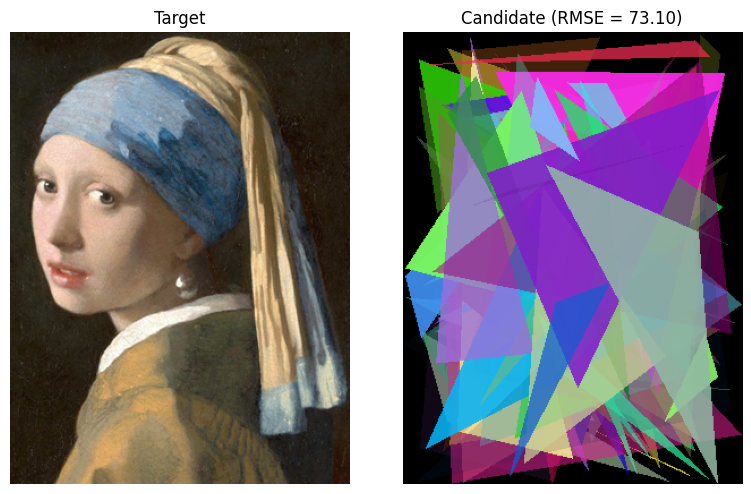

In [6]:
sol.show()

The output generated is a **single random individual**.

<h2 id="chapter4" style="color:#89AC76;">4. Baseline GA Run</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

A single run with sensible defaults to confirm everything works end-to-end.

## test 1

In [ ]:
selector_test1 = AutomaticFitnessSharingSelection(
    sigma_share=25.0,
    alpha=1.0,
    tournament_size=5,
)

In [12]:
SHARING_PARAMS = dict(
    solution_class=TriangleSolution,
    population_size=800,
    n_generations=2000,
    selection_function=selector_test1,
    generation_callback=GenerationCounterCallback(selector_test1),
    crossover_function=uniform_crossover,
    mutation_function=partial(
        triangle_gaussian_mutation,
        sigma_vertex=15,
        sigma_colour=15,
    ),
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=None,
    elitism_n=2,
    n_jobs=-1,
    verbose=True,
    verbose_every=50,
)

best_sol, history, avg_history = genetic_algorithm(**SHARING_PARAMS)
print(f"Best RMSE: {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 58.2566 | avg RMSE: 68.5982 | mut rate: 0.01000
Gen   50 | best RMSE: 32.8578 | avg RMSE: 33.6666 | mut rate: 0.01000
Gen  100 | best RMSE: 28.0484 | avg RMSE: 28.4250 | mut rate: 0.01000
Gen  150 | best RMSE: 25.8494 | avg RMSE: 26.1103 | mut rate: 0.01000
Gen  200 | best RMSE: 24.6900 | avg RMSE: 24.8990 | mut rate: 0.01000
Gen  250 | best RMSE: 23.9693 | avg RMSE: 24.2087 | mut rate: 0.01000
Gen  300 | best RMSE: 23.2487 | avg RMSE: 23.4846 | mut rate: 0.01000
Gen  350 | best RMSE: 22.5265 | avg RMSE: 22.7525 | mut rate: 0.01000
Gen  400 | best RMSE: 21.8822 | avg RMSE: 22.2065 | mut rate: 0.01000
Gen  450 | best RMSE: 21.3920 | avg RMSE: 21.6755 | mut rate: 0.01000
Gen  500 | best RMSE: 21.0386 | avg RMSE: 21.2984 | mut rate: 0.01000
Gen  550 | best RMSE: 20.7007 | avg RMSE: 20.9378 | mut rate: 0.01000
Gen  600 | best RMSE: 20.4649 | avg RMSE: 20.6970 | mut rate: 0.01000
Gen  650 | best RMSE: 20.1604 | avg RMSE: 20.4239 | mut rate: 0.01000
Gen  700 | best RMSE

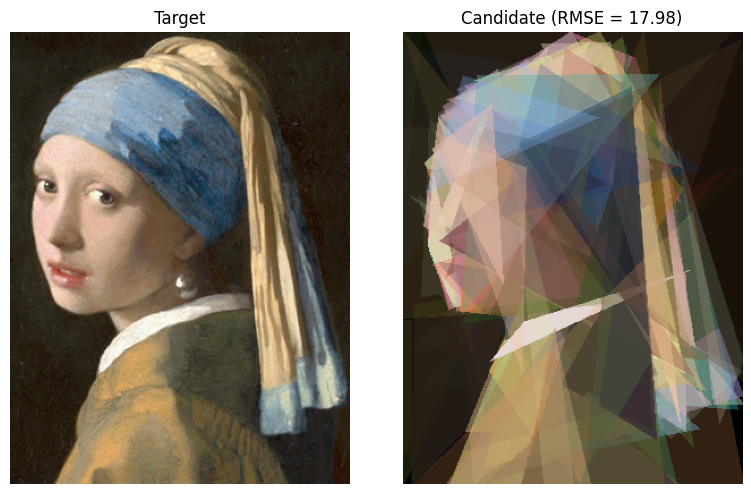

In [13]:
best_sol.show()

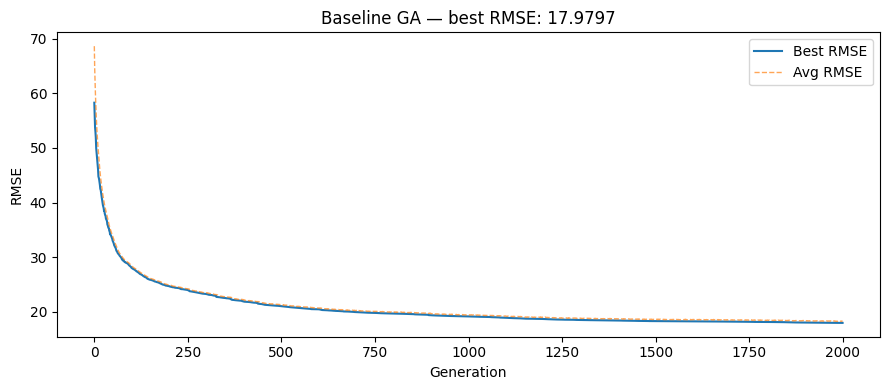

In [14]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {history[-1]:.4f}",
)

## test 2

In [15]:
selector_test2 = AdvancedFitnessSharingSelection(
    sigma_share=0.05, # was 0.15 — tighter niches, less aggressive penalisation
    alpha=1.0,
    tournament_size=5,
)

In [16]:
VERMEER_SUPER_PARAMS = dict(
    solution_class=TriangleSolution,
    population_size=800,
    n_generations=2000,
    selection_function=selector_test2,
    generation_callback=GenerationCounterCallback(selector_test2),
    crossover_function=uniform_crossover,
    mutation_function=partial(
        triangle_gaussian_mutation,
        sigma_vertex=15,
        sigma_colour=15,
    ),
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=None,
    elitism_n=2,
    n_jobs=-1,
    verbose=True,
    verbose_every=50,
)

best_sharing, hist_sharing, avg_hist_sharing = genetic_algorithm(**VERMEER_SUPER_PARAMS)

print("-" * 40)
print(f"Best RMSE: {get_fitness(best_sharing):.4f}")


Gen    0 | best RMSE: 58.5873 | avg RMSE: 68.4050 | mut rate: 0.01000
Gen   50 | best RMSE: 32.9923 | avg RMSE: 33.5796 | mut rate: 0.01000
Gen  100 | best RMSE: 28.5885 | avg RMSE: 28.8348 | mut rate: 0.01000
Gen  150 | best RMSE: 26.6630 | avg RMSE: 26.9731 | mut rate: 0.01000
Gen  200 | best RMSE: 25.6382 | avg RMSE: 25.8953 | mut rate: 0.01000
Gen  250 | best RMSE: 24.5973 | avg RMSE: 24.8809 | mut rate: 0.01000
Gen  300 | best RMSE: 24.0464 | avg RMSE: 24.2687 | mut rate: 0.01000
Gen  350 | best RMSE: 23.7293 | avg RMSE: 23.9533 | mut rate: 0.01000
Gen  400 | best RMSE: 23.4668 | avg RMSE: 23.6709 | mut rate: 0.01000
Gen  450 | best RMSE: 23.1850 | avg RMSE: 23.4513 | mut rate: 0.01000
Gen  500 | best RMSE: 22.8442 | avg RMSE: 23.0959 | mut rate: 0.01000
Gen  550 | best RMSE: 22.6074 | avg RMSE: 22.8607 | mut rate: 0.01000
Gen  600 | best RMSE: 22.4778 | avg RMSE: 22.7495 | mut rate: 0.01000
Gen  650 | best RMSE: 22.3346 | avg RMSE: 22.5941 | mut rate: 0.01000
Gen  700 | best RMSE

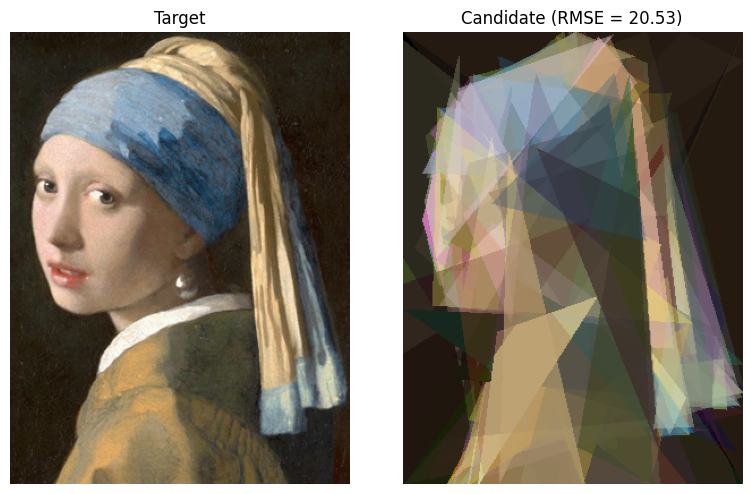

In [17]:
best_sharing.show()

<h3 id="chapter4.1" style="color:#89AC76;">4.1 Convergence Plot</h3>

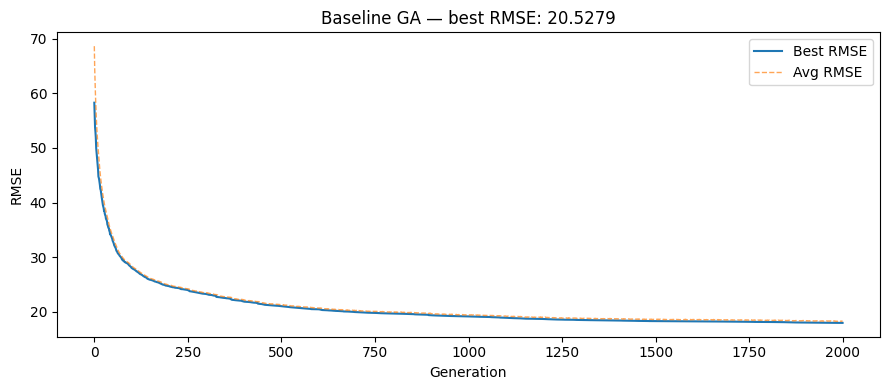

In [18]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {hist_sharing[-1]:.4f}",
)

<h2 id="chapter5" style="color:#89AC76;">5. Hill Climbing for Local Search </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

In [ ]:
ga_rmse_before_hc = get_fitness(best_sol) #from test 1

""" PREVIOUS RESULT - 1.92% IMPROVEMENT:

best_polished_solution, hc_log, hc_evals = hill_climbing(
    solution=best_sol, # best individual from the GA
    max_iterations=30,
    delta_vertex=12.0,
    delta_colour=10.0,
    decay_factor=0.6,
    min_delta=0.1,
    trials_per_iteration=1,
    verbose=True,
)

print(f"\nGA final RMSE  : {ga_rmse_before_hc:.4f}")
print(f"HC final RMSE  : {best_polished_solution.fitness():.4f}")
improvement = ga_rmse_before_hc - best_polished_solution.fitness()
print(f"Improvement    : {improvement:.4f}  ({improvement / ga_rmse_before_hc * 100:.2f} %)")
print(f"Evaluations    : {hc_evals:,}")
"""

best_polished_solution, hc_log, hc_evals = hill_climbing( # 3.71%
    solution=best_sol,
    max_iterations=100, # still improving, give it more budget
    delta_vertex=7.0, # start where it actually worked, skip the wasted iter 1
    delta_colour=6.0, # same reasoning
    decay_factor=0.7, # slower decay, stays at productive scale longer
    min_delta=0.05, # allow finer refinement at the end
    trials_per_iteration=2,# 2 perturbations per triangle per pass
    verbose=True,
)

print(f"\nGA final RMSE : {ga_rmse_before_hc:.4f}")
print(f"HC final RMSE : {best_polished_solution.fitness():.4f}")
improvement = ga_rmse_before_hc - best_polished_solution.fitness()
print(f"Improvement : {improvement:.4f}  ({improvement / ga_rmse_before_hc * 100:.2f} %)")
print(f"Evaluations : {hc_evals:,}")


Hill Climbing start — RMSE: 17.9780 | delta_v=7.00, delta_c=6.00
  Iter   1 | RMSE: 17.9656 | improvements:   10 | delta_v=7.000, delta_c=6.000
  Iter   2 | RMSE: 17.9556 | improvements:    9 | delta_v=7.000, delta_c=6.000
  Iter   3 | RMSE: 17.9419 | improvements:   10 | delta_v=7.000, delta_c=6.000
  Iter   4 | RMSE: 17.9334 | improvements:    4 | delta_v=7.000, delta_c=6.000
  Iter   5 | RMSE: 17.9312 | improvements:    1 | delta_v=7.000, delta_c=6.000
  Iter   6 | RMSE: 17.9152 | improvements:    4 | delta_v=7.000, delta_c=6.000
  Iter   7 | RMSE: 17.9100 | improvements:    4 | delta_v=7.000, delta_c=6.000
  Iter   8 | RMSE: 17.8966 | improvements:    1 | delta_v=7.000, delta_c=6.000
  Iter   9 | RMSE: 17.8811 | improvements:    8 | delta_v=7.000, delta_c=6.000
  Iter  10 | RMSE: 17.8672 | improvements:    4 | delta_v=7.000, delta_c=6.000
  Iter  11 | RMSE: 17.8539 | improvements:    5 | delta_v=7.000, delta_c=6.000
  Iter  12 | RMSE: 17.8520 | improvements:    3 | delta_v=7.000, d

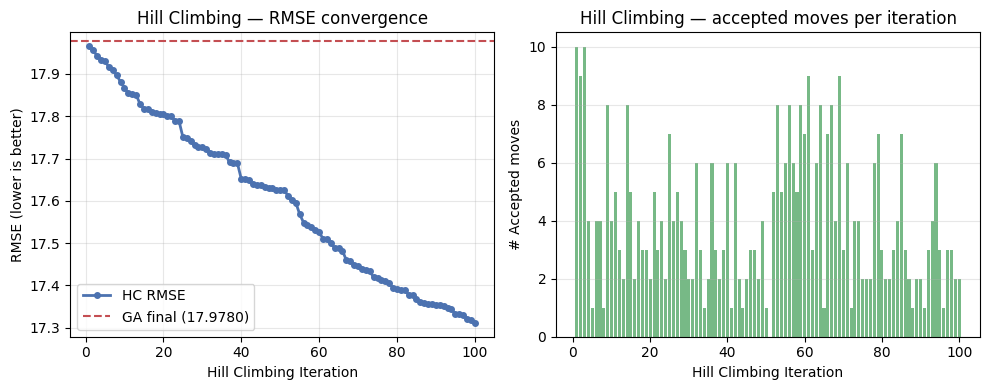

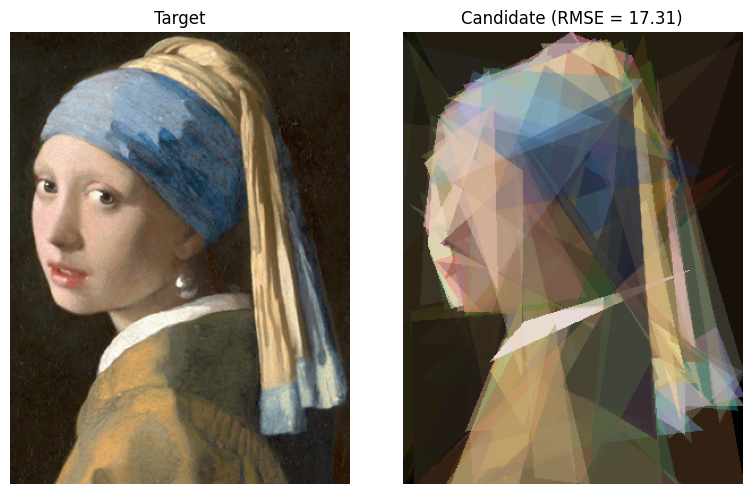

In [24]:
# Visual comparison
plot_hill_climbing_log(hc_log, ga_final_rmse=ga_rmse_before_hc)
best_polished_solution.show()

<h2 id="chapter6" style="color:#89AC76;">6. Best Candidate vs. Target </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

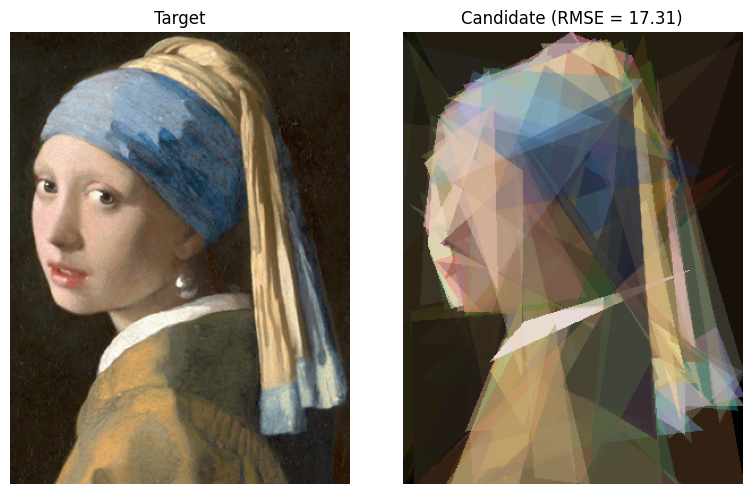

In [26]:
best_polished_solution.show()

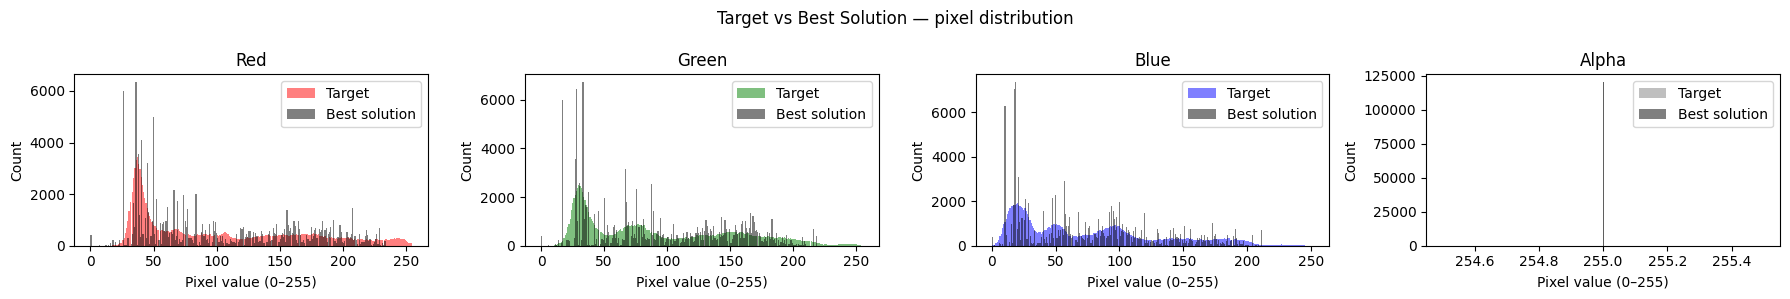

In [27]:
#### Does this make sense???


rendered_arr = np.array(best_sol.get_image())

fig, axes = plt.subplots(1, 4, figsize=(18, 3))
channels = ['Red', 'Green', 'Blue', 'Alpha']
colors   = ['red', 'green', 'blue', 'gray']

for i, (ch, col) in enumerate(zip(channels, colors)):
    axes[i].hist(target_arr[:,:,i].ravel(),   bins=256, color=col,   alpha=0.5, label='Target')
    axes[i].hist(rendered_arr[:,:,i].ravel(), bins=256, color='black', alpha=0.5, label='Best solution')
    axes[i].set_title(ch)
    axes[i].set_xlabel('Pixel value (0–255)')
    axes[i].set_ylabel('Count')
    axes[i].legend()

plt.suptitle('Target vs Best Solution — pixel distribution')
plt.tight_layout()
plt.show()

<h2 id="chapter4" style="color:#89AC76;">6. Exploring genetic operators</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

Try multiple genetic operators and do statistical tests to compare them and, if applicable get the best parameters for them.

<h3 id="chapter6.1" style="color:#89AC76;">6.1 Selection</h3>

try here all of the selection operators and do statistical tests to compare between them

to choose the size of the tournament selection, we need to take into account the size of the population and what is the resulting selection pressure, so that we can scale up the size of the population at the final run

In [28]:
selection_statistical_comparison = run_ga_statistical_comparison(
    "selection_function",
    [
        roulette_wheel_selection,
        rank_based_selection,
        tournament_selection, # default tournament size is 2, # with a population of size 200, this is a selection pressure of 1%
        lambda p: tournament_selection(p, tournament_size=3), # with a population of size 200, this is a selection pressure of 1.5%
        lambda p: tournament_selection(p, tournament_size=5), # with a population of size 200, this is a selection pressure of 2.5%
        lambda p: tournament_selection(p, tournament_size=10), # with a population of size 200, this is a selection pressure of 5%
    ]
)


Starting statistical comparison: 180 GA runs, 36,000 total generations



Progress:   0%|          | 0/36000 [00:02<?, ? gen/s]


KeyboardInterrupt: 

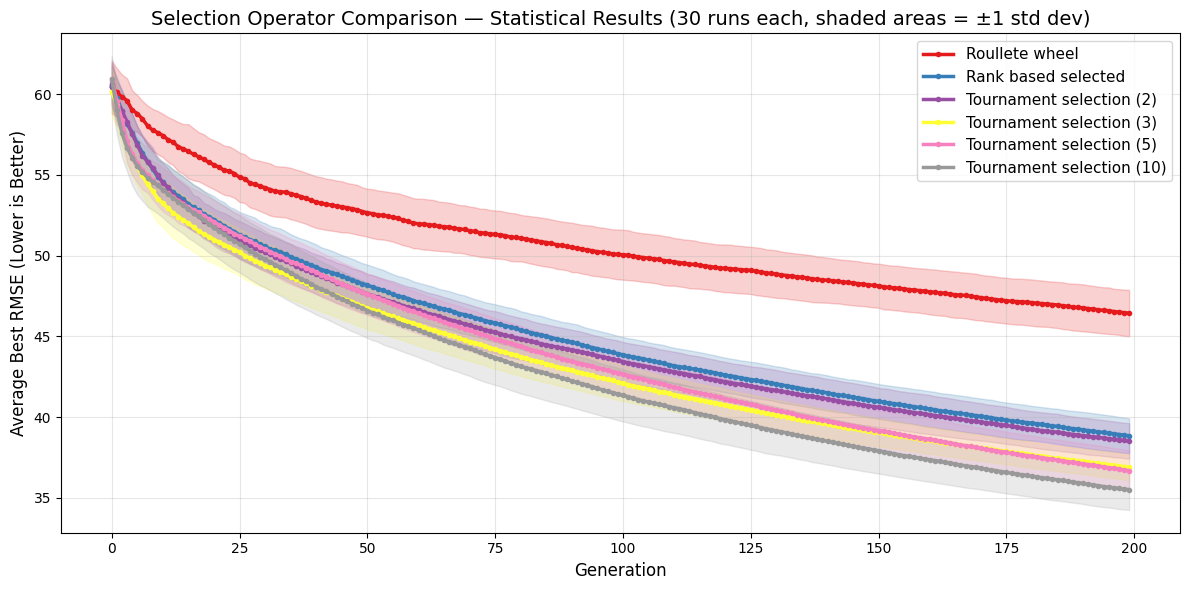

In [9]:
selection_functions = [
    "Roullete wheel",
    "Rank based selected",
    "Tournament selection (2)",
    "Tournament selection (3)",
    "Tournament selection (5)",
    "Tournament selection (10)"
]

plot_statistical_comparison(
    selection_statistical_comparison,
    labels=selection_functions,
    title="Selection Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

based on the results from this statistical comparison, let's try even lower selection pressures in tournament selection

In [10]:
selection_statistical_comparison2 = run_ga_statistical_comparison(
    "selection_function",
    [
        lambda p: tournament_selection(p, tournament_size=10), # with a population of size 200, this is a selection pressure of 5%
        lambda p: tournament_selection(p, tournament_size=15), # with a population of size 200, this is a selection pressure of 7.5%
        lambda p: tournament_selection(p, tournament_size=20), # with a population of size 200, this is a selection pressure of 10%
        lambda p: tournament_selection(p, tournament_size=30), # with a population of size 200, this is a selection pressure of 15%
    ]
)


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [25:55<00:00, 15.42 gen/s]


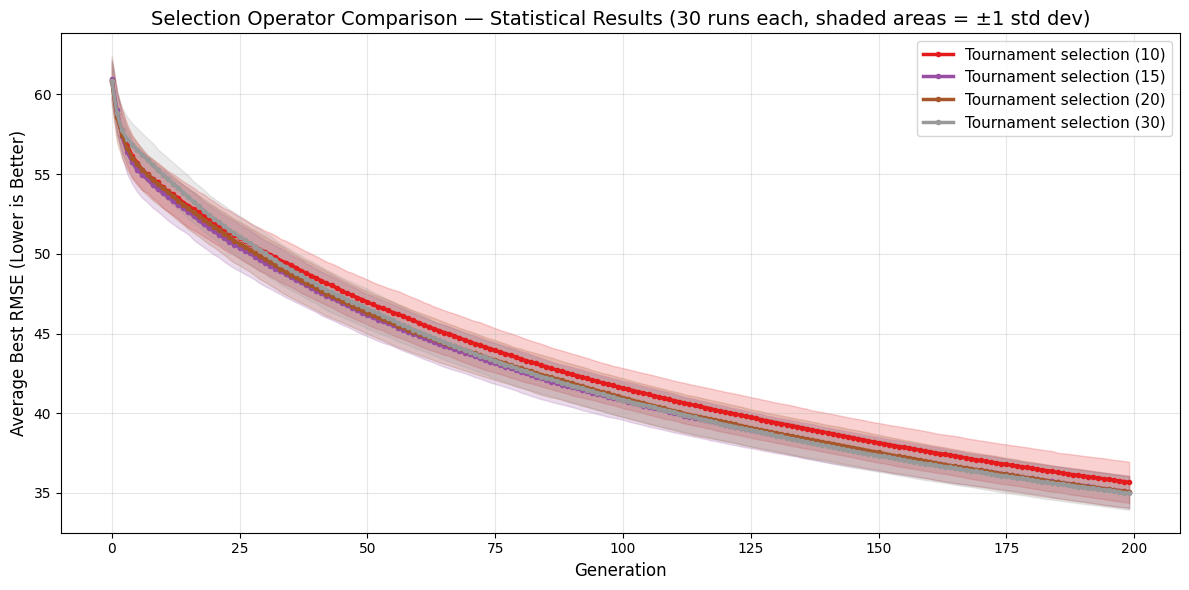

In [11]:
selection_functions = [
    "Tournament selection (10)",
    "Tournament selection (15)",
    "Tournament selection (20)",
    "Tournament selection (30)",
]

plot_statistical_comparison(
    selection_statistical_comparison2,
    labels=selection_functions,
    title="Selection Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

All of the values seem to be statistically equivalent, with all of them being really close together and inside the standard deviations of eachother

<h3 id="chapter6.2" style="color:#89AC76;">6.2 Crossover</h3>

try here all of the crossover operators and do statistical tests to compare between them

In [6]:
crossover_statistical_comparison = run_ga_statistical_comparison(
    "crossover_function",
    [
        one_point_crossover,
        two_point_crossover,
        uniform_crossover,
    ]
)


Starting statistical comparison: 90 GA runs, 18,000 total generations



Progress: 100%|██████████| 18000/18000 [19:27<00:00, 15.42 gen/s]


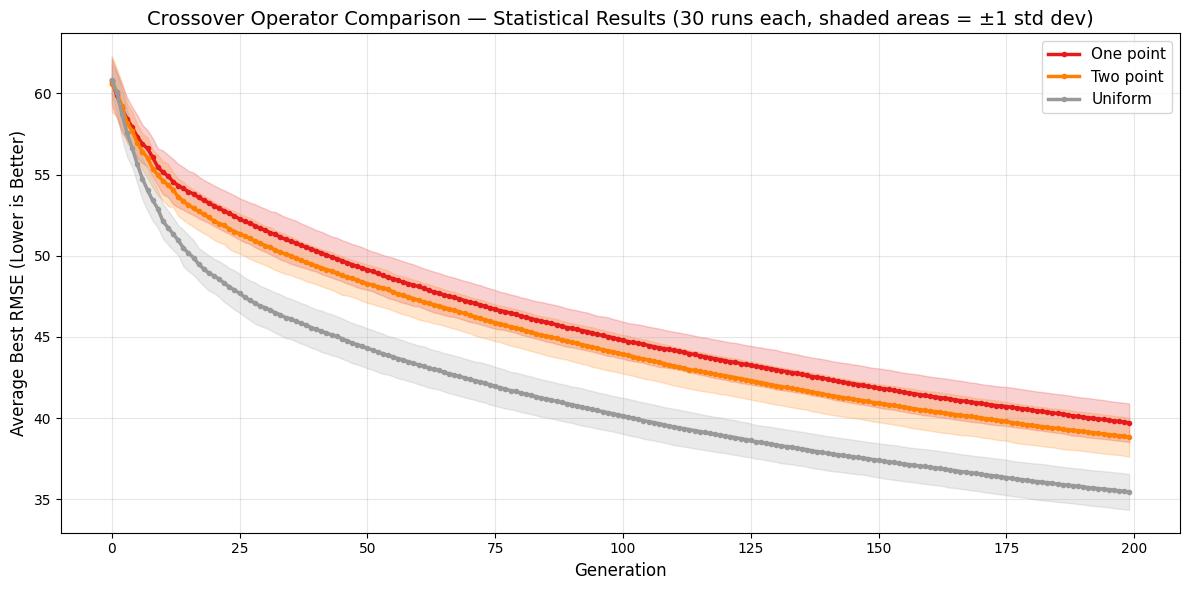

In [7]:
crossover_functions = [
    "One point",
    "Two point",
    "Uniform"
]

plot_statistical_comparison(
    crossover_statistical_comparison,
    labels=crossover_functions,
    title="Crossover Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

<h3 id="chapter6.3" style="color:#89AC76;">6.3 Mutation</h3>

In [9]:
mutation_statistical_comparison = run_ga_statistical_comparison(
    "mutation_function",
    [
        triangle_gaussian_mutation,
        triangle_gaussian_color_mutation,
        triangle_gaussian_vertex_mutation,
        triangle_reset_gene_mutation,
        triangle_reset_mutation,
        triangle_layer_swap_mutation
    ]
)


Starting statistical comparison: 180 GA runs × 200 generations = 36,000 total generations



Progress: 100%|██████████| 180/180 [39:59<00:00, 13.33s/ run]


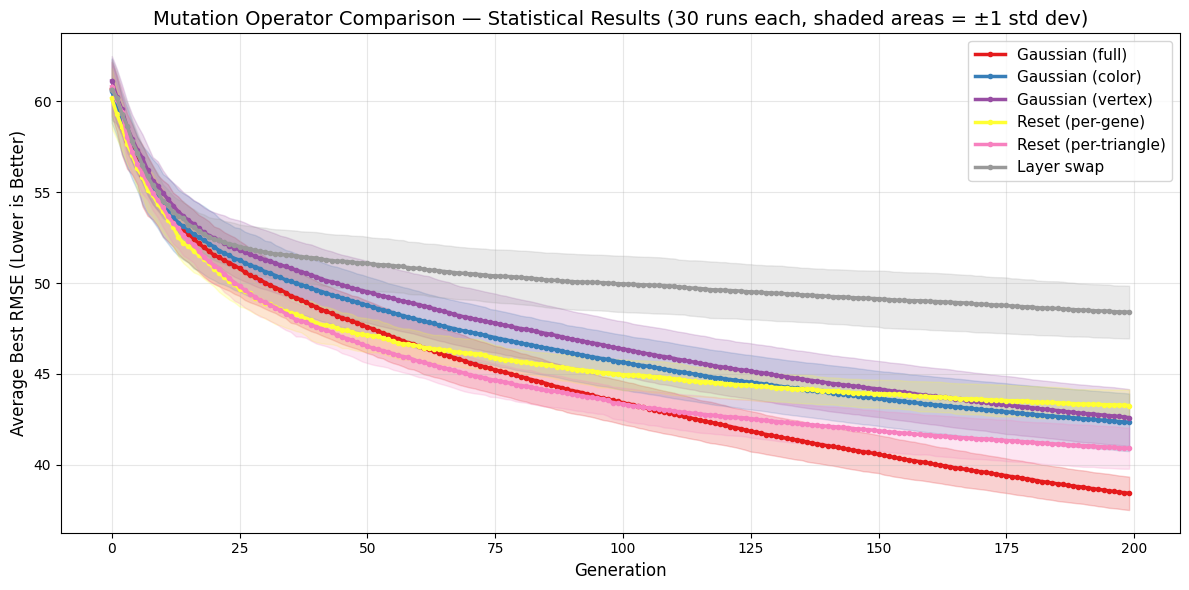

In [ ]:
# Visualize mutation statistical results with standard deviation bands
mutation_modes = [
    "Gaussian (full)",
    "Gaussian (color)",
    "Gaussian (vertex)",
    "Reset (per-gene)",
    "Reset (per-triangle)",
    "Layer swap"
]

plot_statistical_comparison(
    mutation_statistical_comparison,
    labels=mutation_modes,
    title="Mutation Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

<h3 id="chapter6.3.1" style="color:#89AC76;">6.3.1 Adaptive mutation rate</h3>

Now we will test strategies for adapting mutation rates:
- Mutation rate decay
- Self-adaptive mutation rate (gene)

In [3]:
mutation_rate_decay_statistical_comparison = run_ga_statistical_comparison(
    "mutation_rate_decay",
    [
        None,
        0.1,
        0.01,
        0.001,
        0.0001,
        0.00001
    ]
)


Starting statistical comparison: 180 GA runs, 36,000 total generations



Progress: 100%|██████████| 36000/36000 [38:20<00:00, 15.65 gen/s] 


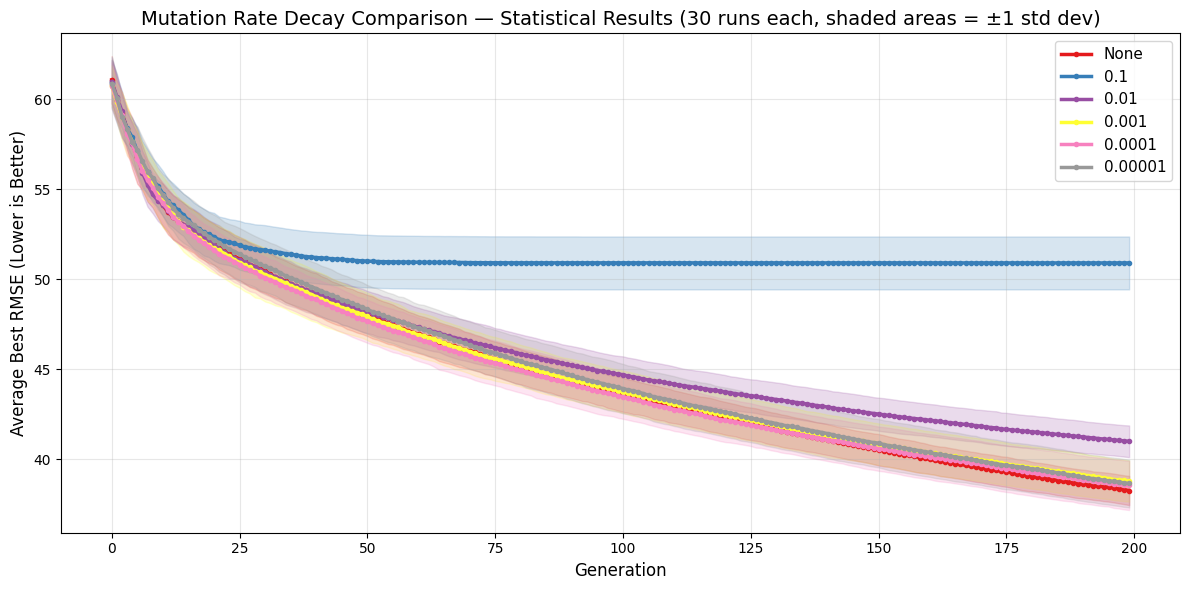

In [4]:
# Visualize mutation statistical results with standard deviation bands
mutation_rate_decay_values = [
    "None",
    "0.1",
    "0.01",
    "0.001",
    "0.0001",
    "0.00001"
]

plot_statistical_comparison(
    mutation_rate_decay_statistical_comparison,
    labels=mutation_rate_decay_values,
    title="Mutation Rate Decay Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [ ]:
adaptive_mutation_rate_statistical_comparison = run_ga_statistical_comparison(
    "solution_class",
    [
        TriangleSolution,
        AdaptiveTriangleSolution
    ]
)


Starting statistical comparison: 60 GA runs × 200 generations = 12,000 total generations



Progress: 100%|██████████| 60/60 [06:23<00:00,  6.40s/ run]


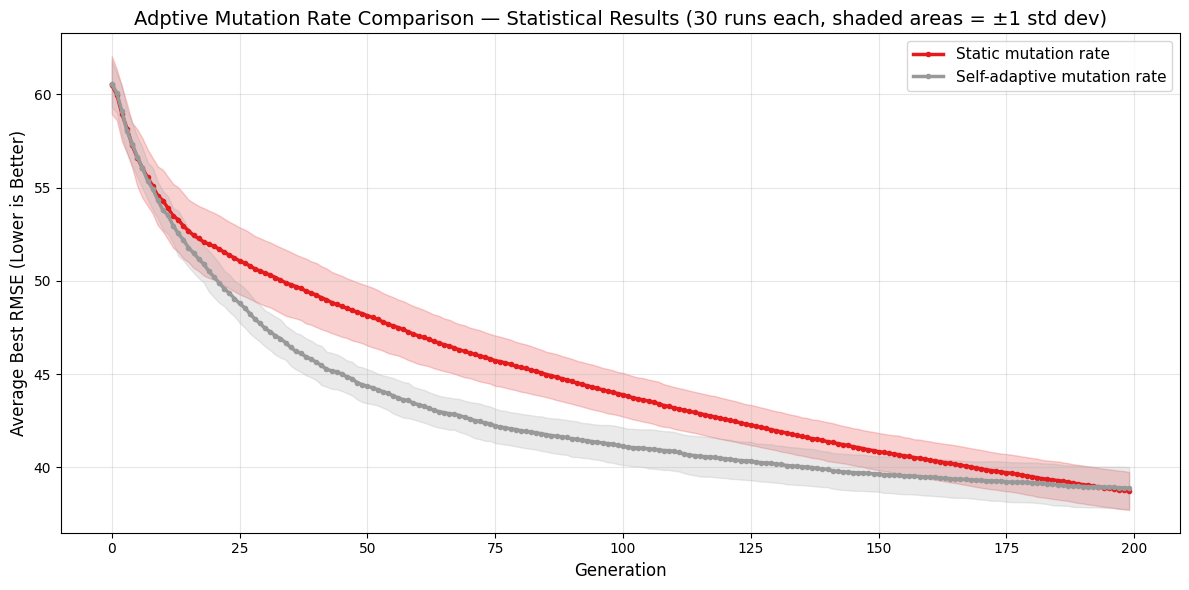

In [7]:
# Visualize mutation statistical results with standard deviation bands
mutation_rate_strategy = [
    "Static mutation rate",
    "Self-adaptive mutation rate"
]

plot_statistical_comparison(
    adaptive_mutation_rate_statistical_comparison,
    labels=mutation_rate_strategy,
    title="Adptive Mutation Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [4]:
adaptive_mutation_rate_statistical_comparison2 = run_ga_statistical_comparison(
    "solution_class",
    [
        TriangleSolution,
        AdaptiveTriangleSolution
    ],
    n_generations=500
)


Starting statistical comparison: 60 GA runs, 30,000 total generations



Progress: 100%|██████████| 30000/30000 [33:49<00:00, 14.78 gen/s]


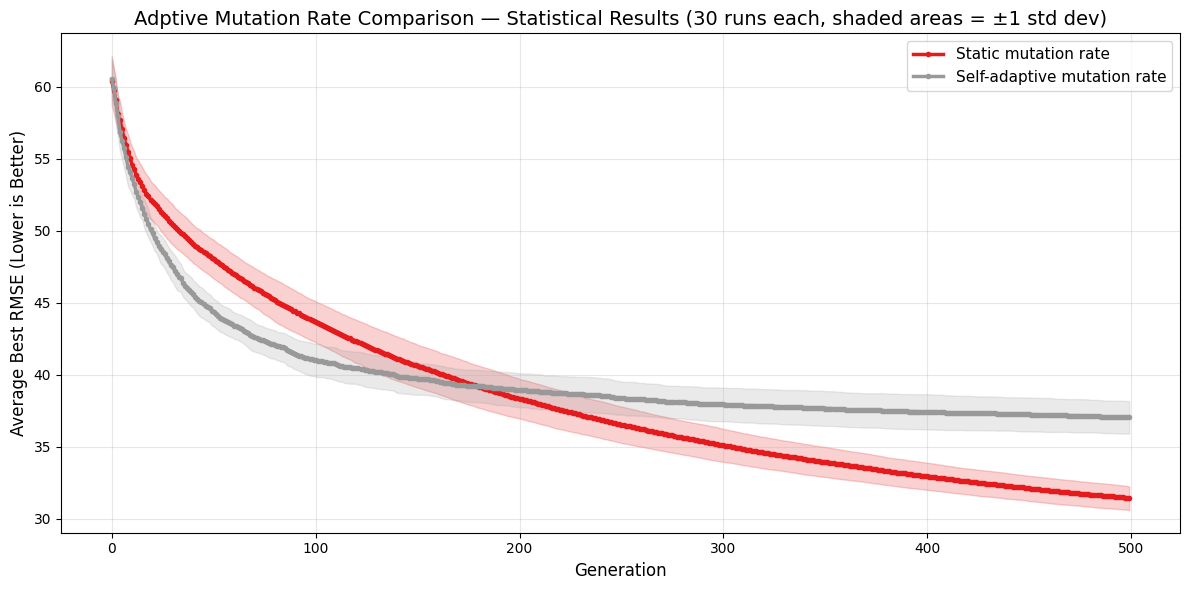

In [5]:
# Visualize mutation statistical results with standard deviation bands
mutation_rate_strategy = [
    "Static mutation rate",
    "Self-adaptive mutation rate"
]

plot_statistical_comparison(
    adaptive_mutation_rate_statistical_comparison2,
    labels=mutation_rate_strategy,
    title="Adptive Mutation Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

## Find the best population size to use

In [17]:
population_size_statistical_comparison = run_ga_statistical_comparison(
    "population_size",
    [
        200,
        400,
        800,
        1500
    ]
)


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [6:07:31<00:00,  1.09 gen/s]  


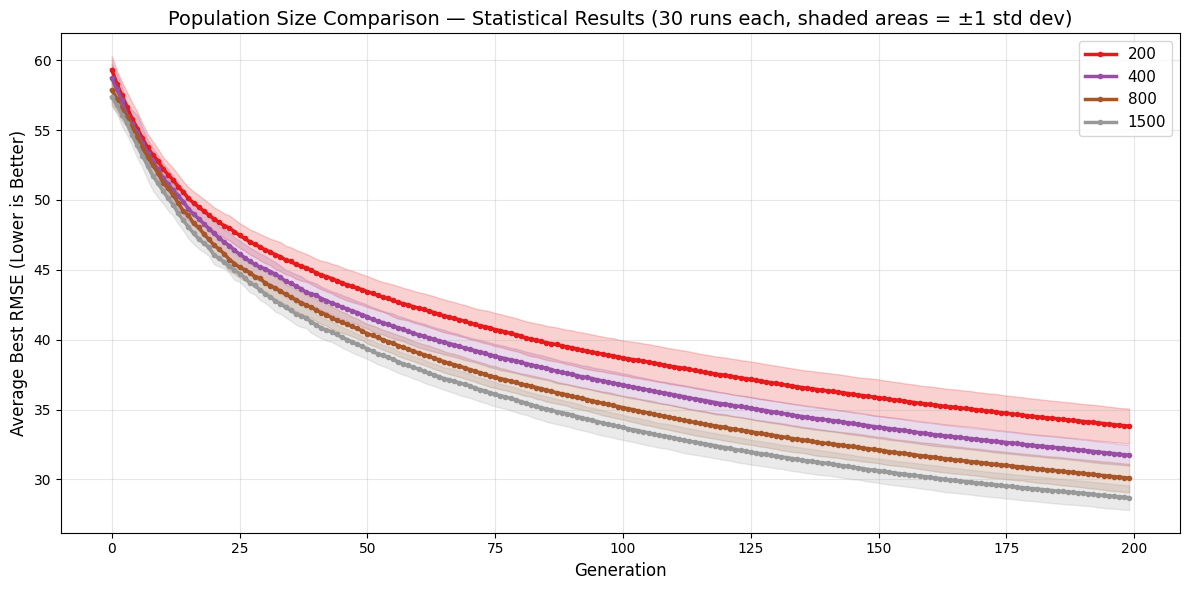

In [18]:
population_sizes = [
    "200",
    "400",
    "800",
    "1500"
]

plot_statistical_comparison(
    population_size_statistical_comparison,
    labels=population_sizes,
    title="Population Size Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

<h2 id="chapter7" style="color:#89AC76;">7. Final GA run </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>


In [19]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=800,
    n_generations=2000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 58.2414 | avg RMSE: 68.5261 | mut rate: 0.01000
Gen   50 | best RMSE: 32.6811 | avg RMSE: 33.0376 | mut rate: 0.01000
Gen  100 | best RMSE: 28.4080 | avg RMSE: 28.5723 | mut rate: 0.01000
Gen  150 | best RMSE: 26.3321 | avg RMSE: 26.4435 | mut rate: 0.01000
Gen  200 | best RMSE: 25.0181 | avg RMSE: 25.1214 | mut rate: 0.01000
Gen  250 | best RMSE: 24.0273 | avg RMSE: 24.1036 | mut rate: 0.01000
Gen  300 | best RMSE: 23.2857 | avg RMSE: 23.3618 | mut rate: 0.01000
Gen  350 | best RMSE: 22.6252 | avg RMSE: 22.7005 | mut rate: 0.01000
Gen  400 | best RMSE: 22.1101 | avg RMSE: 22.1982 | mut rate: 0.01000
Gen  450 | best RMSE: 21.7268 | avg RMSE: 21.8015 | mut rate: 0.01000
Gen  500 | best RMSE: 21.3595 | avg RMSE: 21.4520 | mut rate: 0.01000
Gen  550 | best RMSE: 21.1173 | avg RMSE: 21.2031 | mut rate: 0.01000
Gen  600 | best RMSE: 20.7939 | avg RMSE: 20.8765 | mut rate: 0.01000
Gen  650 | best RMSE: 20.5164 | avg RMSE: 20.6087 | mut rate: 0.01000
Gen  700 | best RMSE

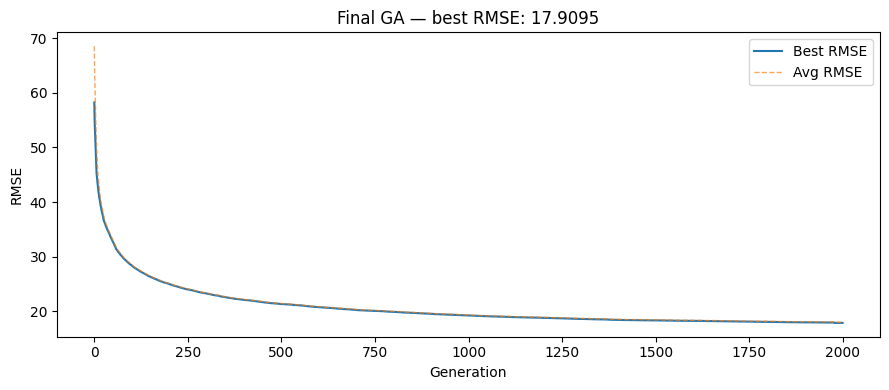

In [22]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Final GA — best RMSE: {history[-1]:.4f}",
)

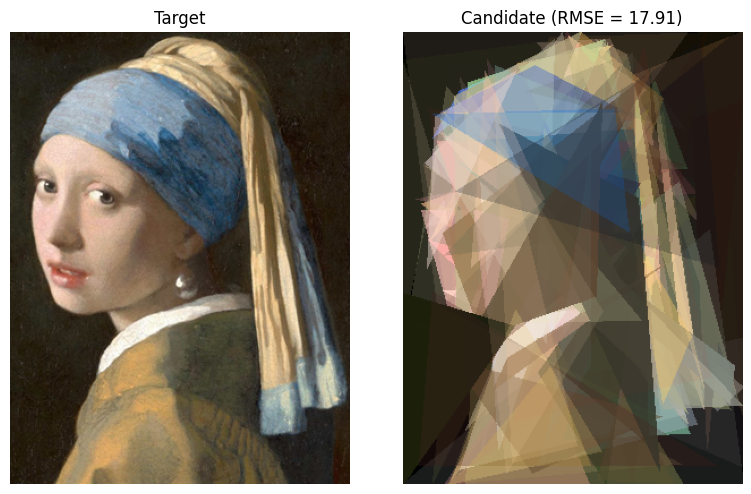

In [20]:
best_sol.show()

<h2 id="chapter4" style="color:#89AC76;">8. Save Best Result </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>


In [21]:
out_path = "best_result.png"
best_sol.get_image().save(out_path)
print(f"Saved best candidate to: {out_path}")

Saved best candidate to: best_result.png


<span style="color:#BA8E23;">

### <h2><strong>CONFIRM IF IS DONE - UPDATE MAIN</strong></h2>
1. **Hybrid GA + Local Search (Hill Climbing or CMA-ES) - ANDRÉ** - CONFIRMAR SE ESTÁ
	- ran Hill Climbing as a local search after the GA converged, using the GA's best solution as the starting point.

**Afonso** - Passar tudo para o main.


### <h2><strong>MEDIUM PRIORITY</strong></h2>
1. **Smarter initialization** - **Cláudio**
- Sample triangle colours from target pixels
- Cuts early RMSE immediately

### <h2><strong>ANALYSIS AND REPORTING </strong></h2>
1. **Wilcoxon statistical tests with a tournament structure**<br>
Use Wilcoxon signed-rank tests to determine which configuration was statistically significantly better, then ran a tournament-style elimination comparing the winner sequentially against challengers.

mas adaptadoa rmse

2. **Search space size**
Frame as continuous space
Show problem awareness

(as it continuous)


</span>